In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Menstrual Hygiene Access in Punjab

Question: Which groups of women in Punjab have the least access to appropriate menstrual hygiene?

Data: Punjab MICS 2017-18, Table WS.4.1

In [2]:
import os
for folder, _, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(folder, f))

/kaggle/input/datasets/eshalfaisal30/punjab-menstrual-data/punjab_data.csv.csv


In [3]:
df = pd.read_csv("/kaggle/input/datasets/eshalfaisal30/punjab-menstrual-data/punjab_data.csv.csv")
df

,group_type,group,appropriate_materials_pct,private_place_pct,both_pct,women_menstruated,source,year
0,Overall,Punjab,88.9,90.2,83.4,68491,Punjab MICS 2017-18 Table WS.4.1,2017
1,Area,Rural,88.4,89.8,82.5,41983,Punjab MICS 2017-18 Table WS.4.1,2017
2,Area,Urban,89.8,90.8,84.8,26508,Punjab MICS 2017-18 Table WS.4.1,2017
3,Education,None/Preschool,84.0,89.0,78.7,22128,Punjab MICS 2017-18 Table WS.4.1,2017
4,Education,Primary,90.9,91.1,85.6,12599,Punjab MICS 2017-18 Table WS.4.1,2017
5,Education,Lower Secondary,91.9,90.4,85.9,7575,Punjab MICS 2017-18 Table WS.4.1,2017
6,Education,Upper Secondary,91.7,90.6,85.9,11951,Punjab MICS 2017-18 Table WS.4.1,2017
7,Education,Higher,90.9,90.8,85.4,14235,Punjab MICS 2017-18 Table WS.4.1,2017
8,Wealth,Poorest,79.3,87.9,73.9,11403,Punjab MICS 2017-18 Table WS.4.1,2017
9,Wealth,Second,90.1,90.8,84.7,13168,Punjab MICS 2017-18 Table WS.4.1,2017


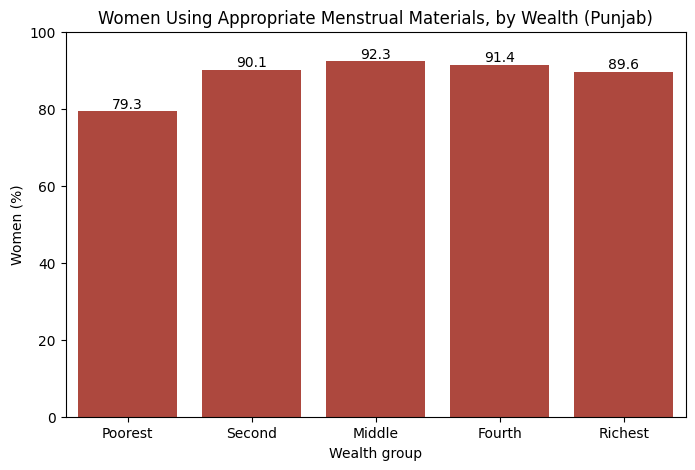

In [4]:
order = ["Poorest", "Second", "Middle", "Fourth", "Richest"]
wealth = df[df["group_type"] == "Wealth"]

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=wealth, x="group", y="appropriate_materials_pct", order=order, color="#c0392b")
ax.bar_label(ax.containers[0])
plt.title("Women Using Appropriate Menstrual Materials, by Wealth (Punjab)")
plt.xlabel("Wealth group")
plt.ylabel("Women (%)")
plt.ylim(0, 100)
plt.show()

**Finding:** Women in the poorest wealth group have the lowest access to appropriate materials at 79.3%. The other four wealth groups are all close together, between 89.6% and 92.3%.

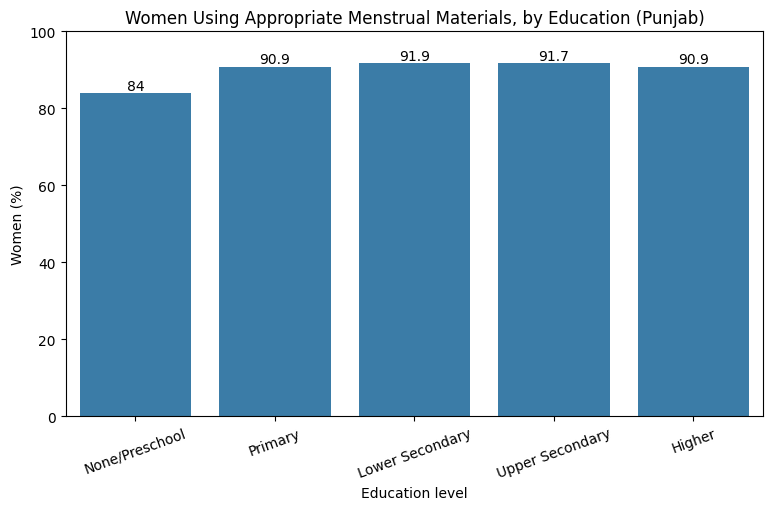

In [5]:
order = ["None/Preschool", "Primary", "Lower Secondary", "Upper Secondary", "Higher"]
edu = df[df["group_type"] == "Education"]

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=edu, x="group", y="appropriate_materials_pct", order=order, color="#2980b9")
ax.bar_label(ax.containers[0])
plt.title("Women Using Appropriate Menstrual Materials, by Education (Punjab)")
plt.xlabel("Education level")
plt.ylabel("Women (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.show()

**Finding:** Women with no education or only preschool have lower access (84.0%) than women with any level of education, who are all between 90.9% and 91.9%.

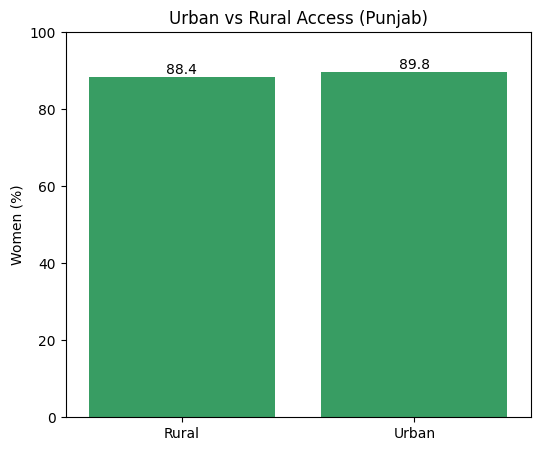

In [6]:
area = df[df["group_type"] == "Area"]

plt.figure(figsize=(6, 5))
ax = sns.barplot(data=area, x="group", y="appropriate_materials_pct", color="#27ae60")
ax.bar_label(ax.containers[0])
plt.title("Urban vs Rural Access (Punjab)")
plt.xlabel("")
plt.ylabel("Women (%)")
plt.ylim(0, 100)
plt.show()

**Finding:** The gap between urban women (89.8%) and rural women (88.4%) is small, only 1.4 percentage points. In Punjab, wealth and education show bigger differences than where a woman lives.

In [7]:
overall = df.loc[df["group_type"] == "Overall", "both_pct"].iloc[0]

groups = df[df["group_type"] != "Overall"].copy()
groups["gap_vs_punjab"] = (groups["both_pct"] - overall).round(1)

groups.sort_values("gap_vs_punjab")[["group_type", "group", "both_pct", "gap_vs_punjab"]]

,group_type,group,both_pct,gap_vs_punjab
8,Wealth,Poorest,73.9,-9.5
3,Education,None/Preschool,78.7,-4.7
1,Area,Rural,82.5,-0.9
12,Wealth,Richest,84.3,0.9
9,Wealth,Second,84.7,1.3
2,Area,Urban,84.8,1.4
7,Education,Higher,85.4,2.0
11,Wealth,Fourth,85.4,2.0
4,Education,Primary,85.6,2.2
6,Education,Upper Secondary,85.9,2.5


## Conclusion

When appropriate materials and a private place to wash and change are counted together, the poorest women (73.9%) and women with no schooling (78.7%) are furthest below the Punjab average of 83.4%. Programs that distribute menstrual hygiene resources should reach these groups first.

**Limitations:** This data is from 2017-18, covers Punjab by group (not by district), and includes women aged 15-49, not only girls.